### This cell will be used to create data that will help machine learning model to predict the proper batches! 

In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
## Creating the dataframe
lunch_time = np.arange(0, 121, 1)
print(lunch_time)

[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120]


### Creating Scenarios : 
#### Slow rush overall 
1. 1 students / minute -> outside rush 
2. 3 students / minute -> inside rush 
### Normal rush overall 
1. 2 students / minute -> outside rush 
2. 5 students / minute -> inside rush 
### Busy rush overall 
1. 3 students / minute -> outside rush 
2. 7 students / minute -> inside rush 

### Generating slow rush data 

In [4]:
rng = np.random.default_rng(42) ## to regenerate the same sample
lunches = []
for i in range(25):
    slow_0 = pd.DataFrame({"minute": np.arange(1, 121),"rate": 1}) ## Total 120 minutes information 
    slow_0.loc[slow_0["minute"].between(1, 30), "rate"] = 3 ## Between the 60-90 minute rush is seen 
    slow_0["arrivals"] = rng.poisson(slow_0["rate"]) ## Poission distirbution where the rate will be maintained
    slow_0["last_5_min"] = (slow_0["arrivals"].rolling(5, min_periods=1).sum()) ## Cumulative sum for first 5
    slow_0["last_10_min"] = (slow_0["arrivals"].rolling(10, min_periods=1).sum()) ## Cumulative sum for first 10 
    slow_0["type"] = "slow" ## Type of rush 
    slow_0['next_10_min'] = slow_0["arrivals"].rolling(10).sum().shift(-10)
    lunches.append(slow_0)
for i in range(25): 
    slow_60 = pd.DataFrame({"minute": np.arange(1, 121),"rate": 1}) ## Total 120 minutes information 
    slow_60.loc[slow_60["minute"].between(61, 90), "rate"] = 3 ## Between the 60-90 minute rush is seen 
    slow_60["arrivals"] = rng.poisson(slow_60["rate"]) ## Poission distirbution where the rate will be maintained
    slow_60["last_5_min"] = (slow_60["arrivals"].rolling(5, min_periods=1).sum()) ## Cumulative sum for first 5
    slow_60["last_10_min"] = (slow_60["arrivals"].rolling(10, min_periods=1).sum()) ## Cumulative sum for first 10 
    slow_60["type"] = "slow" ## Type of rush 
    slow_60['next_10_min'] = slow_60["arrivals"].rolling(10).sum().shift(-10)
    lunches.append(slow_60)

for i in range(25):
    slow_30 = pd.DataFrame({"minute": np.arange(1, 121),"rate": 1}) ## Total 120 minutes information 
    slow_30.loc[slow_30["minute"].between(31, 60), "rate"] = 3 ## Between the 60-90 minute rush is seen 
    slow_30["arrivals"] = rng.poisson(slow_30["rate"]) ## Poission distirbution where the rate will be maintained
    slow_30["last_5_min"] = (slow_30["arrivals"].rolling(5, min_periods=1).sum()) ## Cumulative sum for first 5
    slow_30["last_10_min"] = (slow_30["arrivals"].rolling(10, min_periods=1).sum()) ## Cumulative sum for first 10 
    slow_30["type"] = "slow" ## Type of rush 
    slow_30['next_10_min'] = slow_30["arrivals"].rolling(10).sum().shift(-10)
    lunches.append(slow_30)

for i in range(25):
    slow_90 = pd.DataFrame({"minute": np.arange(1, 121),"rate": 1}) ## Total 120 minutes information 
    slow_90.loc[slow_90["minute"].between(91, 120), "rate"] = 3 ## Between the 60-90 minute rush is seen 
    slow_90["arrivals"] = rng.poisson(slow_90["rate"]) ## Poission distirbution where the rate will be maintained
    slow_90["last_5_min"] = (slow_90["arrivals"].rolling(5, min_periods=1).sum()) ## Cumulative sum for first 5
    slow_90["last_10_min"] = (slow_90["arrivals"].rolling(10, min_periods=1).sum()) ## Cumulative sum for first 10 
    slow_90["type"] = "slow" ## Type of rush 
    slow_90['next_10_min'] = slow_90["arrivals"].rolling(10).sum().shift(-10)
    lunches.append(slow_90)

for lunch_id, lunch in enumerate(lunches, start=1):
    lunch["lunch_id"] = lunch_id

slow_data = pd.concat(lunches, ignore_index=True)

slow_data.head(10)



,minute,rate,arrivals,last_5_min,last_10_min,type,next_10_min,lunch_id
0,1,3,4,4.0,4.0,slow,35.0,1
1,2,3,4,8.0,8.0,slow,32.0,1
2,3,3,5,13.0,13.0,slow,33.0,1
3,4,3,1,14.0,14.0,slow,34.0,1
4,5,3,7,21.0,21.0,slow,32.0,1
5,6,3,1,18.0,22.0,slow,31.0,1
6,7,3,4,18.0,26.0,slow,29.0,1
7,8,3,2,15.0,28.0,slow,29.0,1
8,9,3,2,16.0,30.0,slow,30.0,1
9,10,3,5,14.0,35.0,slow,29.0,1


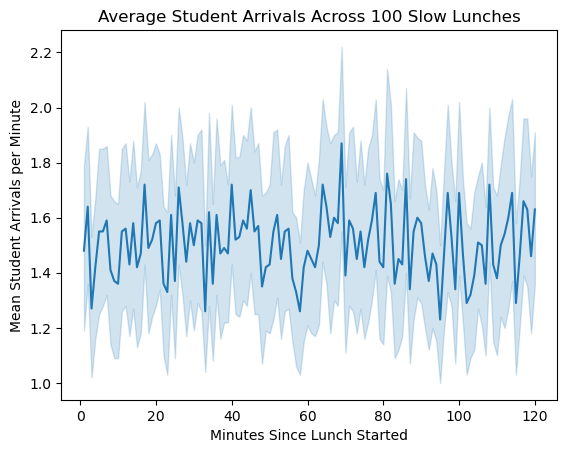

In [5]:
sns.lineplot(x="minute", y="arrivals", data=slow_data)

plt.xlabel("Minutes Since Lunch Started")
plt.ylabel("Mean Student Arrivals per Minute")
plt.title("Average Student Arrivals Across 100 Slow Lunches")
plt.show()


### Medium Rush 

In [ ]:
medium_rush_lunches = []
for i in range(25):
    medium_0 = pd.DataFrame({"minute": np.arange(1, 121),"rate": 2}) ## Total 120 minutes information 
    medium_0.loc[medium_0["minute"].between(1, 30), "rate"] = 5 ## Between the 60-90 minute rush is seen 
    medium_0["arrivals"] = rng.poisson(medium_0["rate"]) ## Poission distirbution where the rate will be maintained
    medium_0["last_5_min"] = (medium_0["arrivals"].rolling(5, min_periods=1).sum()) ## Cumulative sum for first 5
    medium_0["last_10_min"] = (medium_0["arrivals"].rolling(10, min_periods=1).sum()) ## Cumulative sum for first 10 
    medium_0["type"] = "medium" ## Type of rush 
    medium_0['next_10_min'] = medium_0["arrivals"].rolling(10).sum().shift(-10)
    medium_rush_lunches.append(medium_0)
for i in range(25): 
    medium_60 = pd.DataFrame({"minute": np.arange(1, 121),"rate": 2}) ## Total 120 minutes information 
    medium_60.loc[medium_60["minute"].between(61, 90), "rate"] = 5 ## Between the 60-90 minute rush is seen 
    medium_60["arrivals"] = rng.poisson(medium_60["rate"]) ## Poission distirbution where the rate will be maintained
    medium_60["last_5_min"] = (medium_60["arrivals"].rolling(5, min_periods=1).sum()) ## Cumulative sum for first 5
    medium_60["last_10_min"] = (medium_60["arrivals"].rolling(10, min_periods=1).sum()) ## Cumulative sum for first 10 
    medium_60["type"] = "medium" ## Type of rush 
    medium_60['next_10_min'] = medium_60["arrivals"].rolling(10).sum().shift(-10)
    medium_rush_lunches.append(medium_60)

for i in range(25):
    medium_30 = pd.DataFrame({"minute": np.arange(1, 121),"rate": 2}) ## Total 120 minutes information 
    medium_30.loc[medium_30["minute"].between(31, 60), "rate"] = 5 ## Between the 60-90 minute rush is seen 
    medium_30["arrivals"] = rng.poisson(medium_30["rate"]) ## Poission distirbution where the rate will be maintained
    medium_30["last_5_min"] = (medium_30["arrivals"].rolling(5, min_periods=1).sum()) ## Cumulative sum for first 5
    medium_30["last_10_min"] = (medium_30["arrivals"].rolling(10, min_periods=1).sum()) ## Cumulative sum for first 10 
    medium_30["type"] = "medium" ## Type of rush 
    medium_30['next_10_min'] = medium_30["arrivals"].rolling(10).sum().shift(-10)
    medium_rush_lunches.append(medium_30)

for i in range(25):
    medium_90 = pd.DataFrame({"minute": np.arange(1, 121),"rate": 2}) ## Total 120 minutes information 
    medium_90.loc[medium_90["minute"].between(91, 120), "rate"] = 5 ## Between the 60-90 minute rush is seen 
    medium_90["arrivals"] = rng.poisson(medium_90["rate"]) ## Poission distirbution where the rate will be maintained
    medium_90["last_5_min"] = (medium_90["arrivals"].rolling(5, min_periods=1).sum()) ## Cumulative sum for first 5
    medium_90["last_10_min"] = (medium_90["arrivals"].rolling(10, min_periods=1).sum()) ## Cumulative sum for first 10 
    medium_90["type"] = "medium" ## Type of rush 
    medium_90['next_10_min'] = medium_90["arrivals"].rolling(10).sum().shift(-10)
    medium_rush_lunches.append(medium_90)

for lunch_id, lunch in enumerate(medium_rush_lunches, start=1):
    lunch["lunch_id"] = lunch_id

medium_data = pd.concat(medium_rush_lunches, ignore_index=True)

medium_data.head(10)

,minute,rate,arrivals,last_5_min,last_10_min,type,next_10_min,lunch_id
0,1,5,4,4.0,4.0,medium,62.0,1
1,2,5,4,8.0,8.0,medium,64.0,1
2,3,5,5,13.0,13.0,medium,66.0,1
3,4,5,7,20.0,20.0,medium,63.0,1
4,5,5,5,25.0,25.0,medium,65.0,1
5,6,5,7,28.0,32.0,medium,61.0,1
6,7,5,4,28.0,36.0,medium,60.0,1
7,8,5,9,32.0,45.0,medium,57.0,1
8,9,5,9,34.0,54.0,medium,55.0,1
9,10,5,4,33.0,58.0,medium,53.0,1


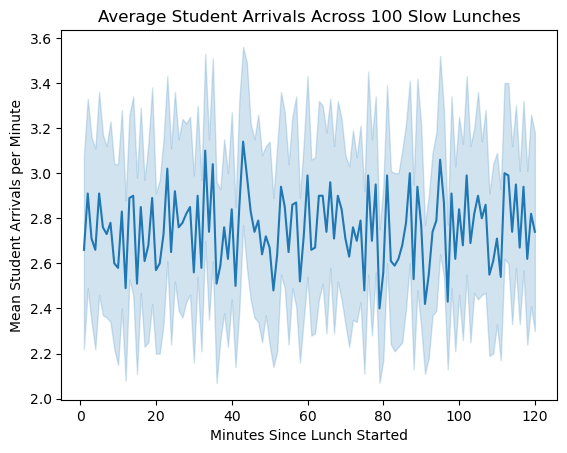

In [9]:
sns.lineplot(x="minute", y="arrivals", data=medium_data)

plt.xlabel("Minutes Since Lunch Started")
plt.ylabel("Mean Student Arrivals per Minute")
plt.title("Average Student Arrivals Across 100 Slow Lunches")
plt.show()

In [ ]:
busy_rush_lunches = []
for i in range(25):
    busy_0 = pd.DataFrame({"minute": np.arange(1, 121),"rate": 3}) ## Total 120 minutes information 
    busy_0.loc[busy_0["minute"].between(1, 30), "rate"] = 7 ## Between the 60-90 minute rush is seen 
    busy_0["arrivals"] = rng.poisson(busy_0["rate"]) ## Poission distirbution where the rate will be maintained
    busy_0["last_5_min"] = (busy_0["arrivals"].rolling(5, min_periods=1).sum()) ## Cumulative sum for first 5
    busy_0["last_10_min"] = (busy_0["arrivals"].rolling(10, min_periods=1).sum()) ## Cumulative sum for first 10 
    busy_0["type"] = "busy" ## Type of rush 
    busy_0['next_10_min'] = busy_0["arrivals"].rolling(10).sum().shift(-10)
    busy_0.append(busy_0)
for i in range(25): 
    medium_60 = pd.DataFrame({"minute": np.arange(1, 121),"rate": 2}) ## Total 120 minutes information 
    medium_60.loc[medium_60["minute"].between(61, 90), "rate"] = 5 ## Between the 60-90 minute rush is seen 
    medium_60["arrivals"] = rng.poisson(medium_60["rate"]) ## Poission distirbution where the rate will be maintained
    medium_60["last_5_min"] = (medium_60["arrivals"].rolling(5, min_periods=1).sum()) ## Cumulative sum for first 5
    medium_60["last_10_min"] = (medium_60["arrivals"].rolling(10, min_periods=1).sum()) ## Cumulative sum for first 10 
    medium_60["type"] = "medium" ## Type of rush 
    medium_60['next_10_min'] = medium_60["arrivals"].rolling(10).sum().shift(-10)
    medium_rush_lunches.append(medium_60)

for i in range(25):
    medium_30 = pd.DataFrame({"minute": np.arange(1, 121),"rate": 2}) ## Total 120 minutes information 
    medium_30.loc[medium_30["minute"].between(31, 60), "rate"] = 5 ## Between the 60-90 minute rush is seen 
    medium_30["arrivals"] = rng.poisson(medium_30["rate"]) ## Poission distirbution where the rate will be maintained
    medium_30["last_5_min"] = (medium_30["arrivals"].rolling(5, min_periods=1).sum()) ## Cumulative sum for first 5
    medium_30["last_10_min"] = (medium_30["arrivals"].rolling(10, min_periods=1).sum()) ## Cumulative sum for first 10 
    medium_30["type"] = "medium" ## Type of rush 
    medium_30['next_10_min'] = medium_30["arrivals"].rolling(10).sum().shift(-10)
    medium_rush_lunches.append(medium_30)

for i in range(25):
    medium_90 = pd.DataFrame({"minute": np.arange(1, 121),"rate": 2}) ## Total 120 minutes information 
    medium_90.loc[medium_90["minute"].between(91, 120), "rate"] = 5 ## Between the 60-90 minute rush is seen 
    medium_90["arrivals"] = rng.poisson(medium_90["rate"]) ## Poission distirbution where the rate will be maintained
    medium_90["last_5_min"] = (medium_90["arrivals"].rolling(5, min_periods=1).sum()) ## Cumulative sum for first 5
    medium_90["last_10_min"] = (medium_90["arrivals"].rolling(10, min_periods=1).sum()) ## Cumulative sum for first 10 
    medium_90["type"] = "medium" ## Type of rush 
    medium_90['next_10_min'] = medium_90["arrivals"].rolling(10).sum().shift(-10)
    medium_rush_lunches.append(medium_90)

for lunch_id, lunch in enumerate(medium_rush_lunches, start=1):
    lunch["lunch_id"] = lunch_id

medium_data = pd.concat(medium_rush_lunches, ignore_index=True)

medium_data.head(10)